<a href="https://colab.research.google.com/github/muhammadrakayansyah-beep/aif_rakah/blob/main/AIF_P3_25120200002_Muhammad_Rakah_Yansyah.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pertemuan 3 Data pinjaman yang siap dianalisis


Dosen **Haikal Shiddiq S.Kom., M.T.**  
Universitas Cakrawala / EKP2166 / Revisi 13 November 2026

**Peran Anda adalah analis finance.** Anda tidak perlu menghafal perintah Python. Untuk setiap langkah, baca tujuan, minta Gemini menjelaskan kode dengan bahasa sehari-hari, jalankan, lalu periksa angka dan tulis kesimpulan sendiri.

### Cara mulai dan bekerja
1. Buka di Google Colab. Pilih **File > Save a copy in Drive**. Beri nama sesuai sesi dan identitas: `AIF_P3_NIM_Nama` atau `AIF_P4_NIM_Nama` untuk AiFn2; `AIF_P3_AiFn1_KelompokXX` atau `AIF_P4_AiFn1_KelompokXX` untuk AiFn1.
2. Klik **Connect**. Jalankan sel kode dari atas ke bawah dengan tombol segitiga. Satu sel adalah satu bagian dokumen. Komputer cloud yang menjalankan kode disebut runtime.
3. Buka panel **Gemini** lewat ikon Gemini/kilauan jika tersedia. Pilih atau sebutkan sel yang ingin dibahas. Tampilan tombol dapat berbeda antarakun. Jangan meminta seluruh notebook ditulis ulang.
4. Sebelum tiap langkah, gunakan prompt: **“Pada notebook ini, jelaskan fungsi Langkah [nomor] untuk mahasiswa finance yang belum pernah coding. Sebutkan tujuan, data masuk, hasil yang muncul, satuan, dan cara membaca satu baris. Jangan ubah atau menjalankan kode dahulu.”** Jika konteks sel tidak terbaca, tempel hanya kode sel latihan yang dimaksud.
5. Cocokkan penjelasan Gemini dengan data. Pada kegiatan membuat kode, minta satu perubahan kecil lalu tinjau sebelum menjalankan. **Kode acuan tersedia tepat di bawah kegiatan**, sehingga kelas tetap berjalan jika Gemini tidak dapat diakses atau hasilnya berbeda.
6. Untuk mengisi jawaban, klik dua kali sel teks **Jawaban Anda**. Simpan output dan penjelasan. Perubahan input perlu diikuti menjalankan ulang sel; hasil lama tidak otomatis diperbarui.

**AiFn2:** praktik dan tugas individual. **AiFn1:** praktik/tugas P3–P4 berkelompok setelah pembentukan kelompok melalui voting dan arahan dosen. Semua anggota mencatat kontribusi dan siap menjelaskan hasil. **Kuis tetap individual tanpa materi, notebook, atau AI.** Jika kelompok belum terbentuk, mulai di salinan masing-masing lalu ikuti arahan pengumpulan dosen.

Data seluruhnya **fiktif untuk pembelajaran**. CPU standar cukup. Tidak perlu GPU, API key, langganan AI, pemasangan Python lokal, atau menghubungkan seluruh Drive. Notebook memuat data yang sama dengan CSV dalam paket, sehingga upload CSV bersifat opsional.

**Tujuan:** memeriksa data, menjelaskan alasan pembersihan, dan membaca rasio cicilan. Kita belum melatih model.

**Jadwal WIB:** AiFn2 19 November 2026 pukul 18.00–20.00; AiFn1 20 November 2026 pukul 08.30–10.00.

In [1]:
# @title Identitas dan kelas
nama_atau_kelompok = "Muhammad Rakah Yansyah" # @param {type:"string"}
nim_atau_daftar_anggota = "25120200002" # @param {type:"string"}
kelas = "AiFn2" # @param ["AiFn2", "AiFn1"]
print("Pemilik:", nama_atau_kelompok)
print("NIM/anggota:", nim_atau_daftar_anggota, "| Kelas:", kelas)

Pemilik: Muhammad Rakah Yansyah
NIM/anggota: 25120200002 | Kelas: AiFn2


In [2]:
# @title Persiapan cukup klik jalankan
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", "_").replace(".", ",").replace("_", "."))
print("Tempat kerja siap. Semua nominal sumber memakai rupiah per bulan.")
print("Pada tampilan ringkas, nominal dikonversi ke Rp juta per bulan dan diberi judul satuan.")

Tempat kerja siap. Semua nominal sumber memakai rupiah per bulan.
Pada tampilan ringkas, nominal dikonversi ke Rp juta per bulan dan diberi judul satuan.


## Langkah 1 Membuka delapan catatan dari P2
**Pertanyaan finance:** apakah satu baris selalu berarti satu pengajuan berbeda?

`id_pengajuan` adalah kode pengajuan. `pendapatan_bulanan` adalah pendapatan pemohon per bulan. `cicilan_bulanan` adalah total cicilan per bulan yang dipakai dalam latihan. Semua nominal sumber dalam rupiah.

**Yang akan muncul:** tabel sumber, jumlah catatan, dan jumlah ID berbeda. `NaN` pada tabel berarti nilai belum tersedia, bukan angka nol.

**Prompt Gemini:** “Jelaskan fungsi Langkah 1. Mengapa menghitung baris dan ID berbeda berguna untuk analis pinjaman? Apa arti NaN? Jelaskan tanpa membahas sintaks.”

In [3]:
# @title Langkah 1 Buka data sumber tanpa mengubahnya
data_awal = pd.DataFrame([['A001', 8000000, 2000000], ['A002', 6000000, 1800000], ['A002', 6000000, 1800000], ['A003', None, 1500000], ['A004', 10000000, 4500000], ['A005', 0, 800000], ['A006', 7000000, -200000], ['A007', 5000000, 2000000]], columns=["id_pengajuan", "pendapatan_bulanan", "cicilan_bulanan"])
display(data_awal)
print("Jumlah catatan:", len(data_awal))
print("Jumlah ID pengajuan berbeda:", data_awal["id_pengajuan"].nunique())
print("Tabel data_awal tetap disimpan sebagai sumber untuk langkah berikutnya.")

,id_pengajuan,pendapatan_bulanan,cicilan_bulanan
0,A001,"8.000.000,00",2000000
1,A002,"6.000.000,00",1800000
2,A002,"6.000.000,00",1800000
3,A003,NaN,1500000
4,A004,"10.000.000,00",4500000
5,A005,"0,00",800000
6,A006,"7.000.000,00",-200000
7,A007,"5.000.000,00",2000000


Jumlah catatan: 8
Jumlah ID pengajuan berbeda: 7
Tabel data_awal tetap disimpan sebagai sumber untuk langkah berikutnya.


### Cara membaca hasil Langkah 1
Jumlah catatan menjawab **berapa baris tersimpan**. Jumlah ID berbeda menjawab **berapa kode pengajuan**. Jika berbeda, periksa penyebabnya sebelum menganggap seluruh baris sebagai nasabah berbeda.

**Jawaban Anda:** jumlah catatan = **8**; jumlah ID berbeda = **7**; saya perlu memeriksa ID **A002** karena muncul dua kali dengan isi yang sama persis (pendapatan Rp6.000.000 dan cicilan Rp1.800.000 per bulan). Jadi 8 baris belum berarti 8 pengajuan berbeda.

## Langkah 2 Memeriksa catatan yang perlu tindakan
**Pertanyaan finance:** angka mana yang belum layak dipakai menghitung rasio?

Pada latihan ini satu ID mewakili satu pengajuan pada satu waktu. Salinan kedua A002 identik di semua kolom dan merupakan kesalahan salin pada data fiktif ini. Di dunia kerja, ID yang berulang belum tentu duplikat jika mewakili periode atau transaksi berbeda.

**Rencana tindakan:** simpan sumber, keluarkan satu salinan identik dari tabel kerja, lalu tandai masalah. Pendapatan kosong perlu dilengkapi. Pendapatan nol membuat rasio tidak terdefinisi. Cicilan negatif tidak sesuai definisi total cicilan latihan.

**Prompt Gemini:** “Mengapa Langkah 2 membedakan kosong, nol, negatif, dan duplikat? Jelaskan alasan finance dari tiap tindakan. Jangan mengisi pendapatan dengan angka tebakan.”

In [4]:
# @title Langkah 2 Buat daftar klarifikasi dan hitung salinan identik
jumlah_duplikat = int(data_awal.duplicated().sum())
data_unik = data_awal.drop_duplicates().copy()
def alasan_klarifikasi(baris):
    if pd.isna(baris["pendapatan_bulanan"]):
        return "Pendapatan belum tersedia; minta bukti/lengkapi sumber"
    if baris["pendapatan_bulanan"] <= 0:
        return "Pendapatan nol/tidak positif; rasio tidak dihitung"
    if pd.isna(baris["cicilan_bulanan"]) or baris["cicilan_bulanan"] < 0:
        return "Cicilan tidak valid menurut definisi latihan; klarifikasi"
    return "Dapat dipakai untuk hitungan latihan"
data_unik["catatan_analis"] = data_unik.apply(alasan_klarifikasi, axis=1)
perlu_klarifikasi = data_unik[data_unik["catatan_analis"] != "Dapat dipakai untuk hitungan latihan"].copy()
display(perlu_klarifikasi[["id_pengajuan", "pendapatan_bulanan", "cicilan_bulanan", "catatan_analis"]])
print("Salinan identik yang dikeluarkan dari tabel kerja:", jumlah_duplikat)
print("Pengajuan yang ditahan untuk klarifikasi:", len(perlu_klarifikasi))
print("Catatan sumber tetap", len(data_awal), "baris. Tidak ada nilai yang ditebak atau ditimpa.")

,id_pengajuan,pendapatan_bulanan,cicilan_bulanan,catatan_analis
3,A003,NaN,1500000,Pendapatan belum tersedia; minta bukti/lengkap...
5,A005,"0,00",800000,Pendapatan nol/tidak positif; rasio tidak dihi...
6,A006,"7.000.000,00",-200000,Cicilan tidak valid menurut definisi latihan; ...


Salinan identik yang dikeluarkan dari tabel kerja: 1
Pengajuan yang ditahan untuk klarifikasi: 3
Catatan sumber tetap 8 baris. Tidak ada nilai yang ditebak atau ditimpa.


### Jawaban Anda untuk Langkah 2
Sebutkan ID yang perlu klarifikasi dan alasan masing-masing. Mengapa mengisi pendapatan yang kosong dengan nol dapat menghasilkan analisis keliru?

Jawaban:
- **A003:** pendapatan kosong (NaN), datanya belum tersedia. Tindakan: ditahan, lalu minta bukti pendapatan (slip gaji atau mutasi rekening).
- **A005:** pendapatan tercatat Rp0. Rasio tidak bisa dihitung karena pembaginya nol. Tindakan: ditahan, lalu konfirmasi apakah memang tidak punya pendapatan atau salah input, dan dari mana cicilan Rp800 ribu dibayar.
- **A006:** cicilan −Rp200.000, padahal cicilan seharusnya tidak negatif. Tindakan: ditahan, lalu cek apakah salah tanda (seharusnya 200.000) atau ada refund atau koreksi yang tercatat di kolom ini.
- **A002:** salinan kedua dikeluarkan dari tabel kerja karena identik di semua kolom (kesalahan salin). Satu catatan A002 tetap dipakai, dan data sumber tidak diubah.

Kalau pendapatan kosong diisi nol, arti datanya berubah. "Belum tahu" malah dianggap "tidak punya pendapatan". A003 akan ikut bermasalah seperti A005 (rasio tidak terdefinisi), padahal bisa saja pendapatannya cukup. Akibatnya ringkasan dan kesimpulan jadi keliru, dan kita memakai angka tebakan, bukan bukti.

## Langkah 3 Membentuk tabel kerja dan menghitung rasio
**Pertanyaan finance:** setelah pemeriksaan, berapa pengajuan yang dapat dianalisis dengan data yang tersedia?

Rasio cicilan = cicilan bulanan ÷ pendapatan bulanan × 100%. Contoh Rp2 juta ÷ Rp8 juta = 25%.

**Yang akan muncul:** hanya pengajuan yang memiliki pendapatan positif dan cicilan tidak negatif. Pengajuan tertahan tetap ada pada daftar klarifikasi. Keputusan ini adalah aturan kerja latihan, bukan kebijakan kredit umum.

**Prompt Gemini:** “Jelaskan fungsi Langkah 3 dan cara membaca satu baris hasil. Apakah rasio yang tinggi otomatis salah data? Apakah tabel ini sudah menghasilkan persetujuan pinjaman?”

In [5]:
# @title Langkah 3 Tabel kerja yang memenuhi definisi latihan
data_valid = data_unik[data_unik["catatan_analis"] == "Dapat dipakai untuk hitungan latihan"].copy()
data_valid["rasio_persen"] = data_valid["cicilan_bulanan"] / data_valid["pendapatan_bulanan"] * 100
tabel_baca = pd.DataFrame({
    "ID": data_valid["id_pengajuan"],
    "Pendapatan Rp juta/bulan": data_valid["pendapatan_bulanan"] / 1e6,
    "Cicilan Rp juta/bulan": data_valid["cicilan_bulanan"] / 1e6,
    "Rasio cicilan %": data_valid["rasio_persen"]})
display(tabel_baca.round(2).reset_index(drop=True))
print("Rekonsiliasi:", len(data_awal), "catatan sumber =", jumlah_duplikat, "salinan +", len(perlu_klarifikasi), "perlu klarifikasi +", len(data_valid), "valid untuk hitungan.")
print("Valid untuk hitungan berarti angka memenuhi definisi latihan, bukan layak menerima kredit.")

,ID,Pendapatan Rp juta/bulan,Cicilan Rp juta/bulan,Rasio cicilan %
0,A001,"8,00","2,00","25,00"
1,A002,"6,00","1,80","30,00"
2,A004,"10,00","4,50","45,00"
3,A007,"5,00","2,00","40,00"


Rekonsiliasi: 8 catatan sumber = 1 salinan + 3 perlu klarifikasi + 4 valid untuk hitungan.
Valid untuk hitungan berarti angka memenuhi definisi latihan, bukan layak menerima kredit.


## Langkah 4 Membaca ringkasan dan grafik
**Pertanyaan finance:** bagaimana sebaran rasio pada pengajuan yang datanya valid?

Rata-rata menjumlahkan rasio lalu membaginya dengan jumlah pengajuan valid. Median adalah nilai tengah setelah pengurutan. Angka ringkasan hanya mewakili tabel yang dianalisis.

**Cara membaca grafik:** tinggi batang menunjukkan rasio dalam persen, bukan jumlah rupiah atau peluang gagal bayar. Rasio A004 yang lebih tinggi perlu konteks tambahan dan tetap dipertahankan karena angkanya valid.

**Prompt Gemini:** “Jelaskan hasil Langkah 4. Data siapa yang masuk rata-rata? Mengapa A004 tidak boleh dibuang hanya karena rasionya lebih tinggi?”

Rata-rata rasio pada 4 pengajuan valid: 35.00%
Median rasio pada kelompok yang sama: 35.00%


,id_pengajuan,rasio_persen
0,A001,"25,00"
1,A002,"30,00"
2,A007,"40,00"
3,A004,"45,00"


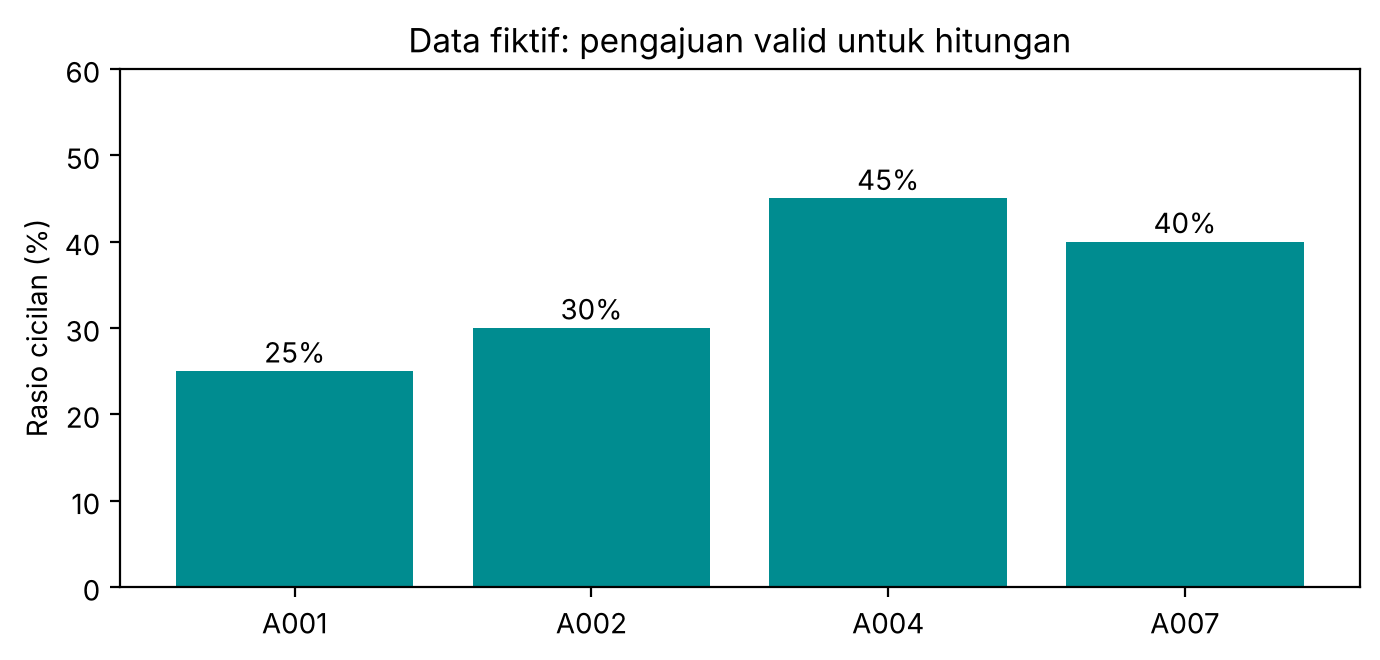

Ringkasan ini belum mewakili seluruh pemohon karena tiga pengajuan masih memerlukan klarifikasi.


In [6]:
# @title Langkah 4 Ringkasan empat pengajuan valid
rata_rata_rasio = float(data_valid["rasio_persen"].mean())
median_rasio = float(data_valid["rasio_persen"].median())
print(f"Rata-rata rasio pada {len(data_valid)} pengajuan valid: {rata_rata_rasio:.2f}%")
print(f"Median rasio pada kelompok yang sama: {median_rasio:.2f}%")
urut = data_valid.sort_values("rasio_persen")
display(urut[["id_pengajuan", "rasio_persen"]].reset_index(drop=True))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(data_valid["id_pengajuan"], data_valid["rasio_persen"], color="#008C90")
ax.set_ylabel("Rasio cicilan (%)"); ax.set_ylim(0, 60)
ax.set_title("Data fiktif: pengajuan valid untuk hitungan")
for i,v in enumerate(data_valid["rasio_persen"]): ax.text(i,v+1,f"{v:.0f}%",ha="center")
plt.tight_layout(); plt.show()
print("Ringkasan ini belum mewakili seluruh pemohon karena tiga pengajuan masih memerlukan klarifikasi.")

### Jawaban Anda untuk Langkah 4
Jelaskan satu temuan dan satu keterbatasan ringkasan. Informasi apa lagi yang dibutuhkan untuk memahami kemampuan membayar pemohon?

Jawaban:
- **Temuan:** rata-rata dan median rasio pada 4 pengajuan valid sama-sama **35%**. Artinya, rata-rata sekitar sepertiga pendapatan bulanan dipakai untuk cicilan. Rasio tertinggi ada di A004 (45%) dan terendah di A001 (25%).
- **Keterbatasan:** ringkasan ini hanya mewakili 4 pengajuan yang datanya lengkap (A001, A002, A004, A007). Tiga pengajuan yang ditahan (A003, A005, A006) tidak ikut dihitung, jadi angka 35% belum mewakili semua pemohon. Datanya juga sedikit dan fiktif.
- **Informasi lain yang dibutuhkan:** pengeluaran rutin atau biaya hidup, jumlah tanggungan, kewajiban lain di luar cicilan latihan, tabungan atau aset, stabilitas pendapatan, dan riwayat pembayaran. Rasio saja belum cukup untuk menilai kemampuan membayar.

## Langkah 5 Meminta Gemini membuat satu hitungan tambahan
**Pertanyaan finance:** berapa pendapatan yang tersisa setelah cicilan, sebelum pengeluaran rutin?

Salin prompt berikut ke Gemini. Tinjau apakah kodenya hanya menambah tabel baru. Tempel kode hasilnya di sel kosong berikut, kemudian jalankan. Jika Gemini tidak tersedia atau hasilnya belum sesuai, jalankan kode acuan di bawahnya. Catat jalur yang digunakan.

> Gunakan data_valid yang sudah ada. Buat SATU sel Python untuk membuat tabel baru bernama hasil_gemini_p3 berisi ID, pendapatan_bulanan, cicilan_bulanan, dan sisa_setelah_cicilan = pendapatan_bulanan - cicilan_bulanan. Semua nominal dalam rupiah per bulan. Jangan mengubah data_awal atau data_valid, menebak data kosong, membuat keputusan kredit, menginstal paket, atau mengakses internet. Tampilkan tabel dan jelaskan bahwa sisa tersebut belum dikurangi pengeluaran rutin. Tunggu saya meninjau kode sebelum menjalankannya.

**Pemeriksaan sendiri:** A001 memakai Rp8 juta dikurangi Rp2 juta. Sisa ini belum memperhitungkan biaya hidup, tabungan, maupun kewajiban lain.

In [7]:
# Tempel kode Gemini untuk Langkah 5 di bawah ini setelah ditinjau.
# Jika tidak memakai Gemini, biarkan sel ini dan gunakan kode acuan berikut.
# Catatan: pada versi ini Langkah 5 dikerjakan memakai kode acuan (Gemini belum dipakai).

In [8]:
# @title Kode acuan Langkah 5 jika diperlukan
hasil_acuan_p3 = data_valid[["id_pengajuan", "pendapatan_bulanan", "cicilan_bulanan"]].copy()
hasil_acuan_p3["sisa_setelah_cicilan"] = hasil_acuan_p3["pendapatan_bulanan"] - hasil_acuan_p3["cicilan_bulanan"]
display(hasil_acuan_p3.reset_index(drop=True))
print("Satuan rupiah/bulan. Sisa ini belum dikurangi pengeluaran rutin dan bukan laba.")
if "hasil_gemini_p3" in globals():
    print("Bandingkan angka tabel Gemini dengan kode acuan. Jelaskan perbedaan jika ada.")

,id_pengajuan,pendapatan_bulanan,cicilan_bulanan,sisa_setelah_cicilan
0,A001,"8.000.000,00",2000000,"6.000.000,00"
1,A002,"6.000.000,00",1800000,"4.200.000,00"
2,A004,"10.000.000,00",4500000,"5.500.000,00"
3,A007,"5.000.000,00",2000000,"3.000.000,00"


Satuan rupiah/bulan. Sisa ini belum dikurangi pengeluaran rutin dan bukan laba.


## Langkah 6 Catatan analis dan pengumpulan
### Jawaban Anda
1. Jelaskan fungsi Langkah 1 dan Langkah 3 dengan kata-kata sendiri, masing-masing maksimal dua kalimat.
2. Tuliskan rekonsiliasi catatan sumber, salinan identik, pengajuan perlu klarifikasi, dan pengajuan valid.
3. Jelaskan mengapa A003 berbeda dari A005 dan mengapa A004 tetap dipertahankan.
4. Jelaskan rasio A001 dan A004. Mengapa rata-rata kelompok valid tidak otomatis mewakili seluruh pengajuan?
5. Baca sisa setelah cicilan A001. Mengapa angka itu belum cukup untuk menyimpulkan kemampuan membayar?
6. Tulis catatan analis 100–150 kata tentang kesiapan data, temuan, keterbatasan, dan tindak lanjut klarifikasi.
7. Nyatakan bantuan Gemini: prompt, tujuan, bagian hasil yang diperiksa, koreksi, serta jalur Gemini/kode acuan. Jika tanpa Gemini, sebutkan kendalanya.
8. AiFn1: daftar anggota, peran, bukti kontribusi masing-masing, dan satu penjelasan/refleksi dari setiap anggota. AiFn2: seluruh jawaban dan eksekusi milik sendiri.

**Jawaban:**

**1. Fungsi Langkah 1 dan Langkah 3**
- *Langkah 1* membuka data sumber apa adanya tanpa diubah, lalu menghitung jumlah baris dan jumlah ID berbeda. Tujuannya mengecek apakah setiap baris benar-benar satu pengajuan.
- *Langkah 3* membentuk tabel kerja yang berisi pengajuan dengan pendapatan positif dan cicilan tidak negatif, lalu menghitung rasio cicilan ÷ pendapatan × 100%. Hasilnya angka yang valid untuk dihitung, bukan keputusan kredit.

**2. Rekonsiliasi**

| Komponen | Jumlah | ID |
|---|---|---|
| Catatan sumber | 8 | A001, A002, A002, A003, A004, A005, A006, A007 |
| Salinan identik dikeluarkan | 1 | A002 (salinan kedua) |
| Perlu klarifikasi (ditahan) | 3 | A003, A005, A006 |
| Valid untuk hitungan | 4 | A001, A002, A004, A007 |

Cek: 8 = 1 + 3 + 4. ID berbeda = 7 = 3 + 4. Tidak ada catatan yang hilang tanpa alasan, dan `data_awal` tetap 8 baris.

**3. A003 vs A005, dan A004**
A003 pendapatannya **kosong**, artinya datanya belum ada sehingga tidak bisa dihitung. A005 pendapatannya **ada tapi nol**, jadi tidak bisa dipakai sebagai pembagi rasio dan janggal karena tetap punya cicilan. Pertanyaan klarifikasi untuk keduanya berbeda. A004 tetap dipertahankan karena datanya lengkap dan sesuai definisi (pendapatan Rp10 juta, cicilan Rp4,5 juta). Rasio 45% memang tinggi, tetapi itu karakteristik pemohon, bukan kesalahan data. Membuangnya hanya karena tinggi akan membuat ringkasan terlihat lebih baik dari kenyataannya.

**4. Rasio A001 dan A004**
- A001: Rp2.000.000 ÷ Rp8.000.000 × 100% = **25%**, seperempat pendapatan untuk cicilan.
- A004: Rp4.500.000 ÷ Rp10.000.000 × 100% = **45%**, hampir setengah pendapatan untuk cicilan.
- Rata-rata (25 + 30 + 45 + 40) ÷ 4 = **35%**. Median (30 + 40) ÷ 2 = **35%**.
Rata-rata ini tidak otomatis mewakili semua pengajuan karena hanya dihitung dari 4 dari 7 pengajuan. Kalau data A003, A005, dan A006 sudah diklarifikasi, nilainya bisa berubah.

**5. Sisa setelah cicilan A001**
Rp8.000.000 − Rp2.000.000 = **Rp6.000.000 per bulan** (hasil kode acuan sama). Hasil lain: A002 Rp4,2 juta, A004 Rp5,5 juta, A007 Rp3 juta. Angka ini belum cukup untuk menyimpulkan kemampuan membayar karena belum dikurangi biaya hidup, tanggungan, tabungan, dan kewajiban lain. Sisa ini juga bukan laba, karena tidak memperhitungkan pengeluaran lain.

**6. Catatan analis**
Data sumber berisi 8 catatan dengan 7 ID berbeda. Satu salinan identik A002 dikeluarkan dari tabel kerja, dan tiga pengajuan ditahan untuk klarifikasi: A003 pendapatannya kosong, A005 pendapatannya nol, dan A006 cicilannya negatif. Tersisa 4 pengajuan valid untuk hitungan, yaitu A001, A002, A004, dan A007. Rata-rata dan median rasio cicilan keempatnya sama-sama 35%. Temuan utama: A004 punya rasio tertinggi, 45%, jadi hampir setengah pendapatannya dipakai untuk cicilan. Datanya valid sehingga tetap dipertahankan dan hanya perlu konteks tambahan. Keterbatasannya, ringkasan ini hanya mewakili 4 dari 7 pengajuan, dan sisa setelah cicilan belum dikurangi biaya hidup. Tindak lanjut: minta bukti pendapatan A003, konfirmasi pendapatan nol A005, dan cek penyebab cicilan negatif A006. Hasil ini belum merupakan keputusan kredit.

**7. Deklarasi bantuan AI**
- *Gemini:* belum digunakan. Langkah 5 dikerjakan memakai **kode acuan** dari dosen (`hasil_acuan_p3`), dan sel kode Gemini dibiarkan kosong.
- *AI lain:* Claude (Anthropic), untuk membantu menjalankan notebook dan membuat draf jawaban.
- *Pemeriksaan sendiri:* menjalankan ulang semua sel di Colab, mencocokkan rekonsiliasi 8 = 1 + 3 + 4, menghitung manual rasio A001 (25%) dan A004 (45%), rata-rata dan median 35%, serta sisa A001 Rp6 juta, lalu menulis ulang jawaban dengan kata-kata sendiri.

**8. AiFn2:** seluruh jawaban dan eksekusi dikerjakan individual (tidak berkelompok).

### Checklist sebelum mengirim
- [ ] Identitas dan kontribusi lengkap.
- [ ] Sel kode dijalankan dari atas, hasil tersimpan, dan jawaban memakai bahasa sendiri.
- [ ] Prompt/bantuan AI dicatat. Angka diperiksa dan keterbatasan disebutkan.
- [ ] Tautan salinan pribadi/kelompok dapat dibaca dosen sebagai Viewer; kirim melalui LMS.
- [ ] Jika pembagian tautan dibatasi, unduh `.ipynb` dengan output dan kirim melalui LMS sesuai instruksi.

Tenggat, email penilai, dan besaran penalti keterlambatan mengikuti pengumuman dosen di LMS. Jika perangkat/koneksi gagal, kerjakan lembar cadangan pada dokumen Tugas P3 dan lengkapi eksekusi kemudian sesuai tenggat pengganti dosen.